# DATASET LOADING

In [ ]:

# ============================================================
# STEP 1: POWER INDUSTRY TRAINING DATASET
# Option C: BERT/RAG + Generative LLM + DMQN
# ============================================================

import os
import pandas as pd
import numpy as np

# 1. Define dataset path
file_path = r"F:\New_File_Dataset\dispatcher_training_dataset.csv"

# 2. Check whether the file exists
if not os.path.isfile(file_path):
    raise FileNotFoundError(
        f"Dataset not found at: {file_path}\n"
        "Please verify the drive, folder, and filename."
    )

# 3. Load CSV dataset
df = pd.read_csv(file_path, encoding="utf-8-sig")

# 4. Display basic dataset information
print("=" * 70)
print("STEP 1: POWER INDUSTRY TRAINING DATASET")
print("=" * 70)

print(f"\nDataset path       : {file_path}")
print(f"Number of records  : {df.shape[0]}")
print(f"Number of columns  : {df.shape[1]}")

# 5. Display column names
print("\n--- COLUMN NAMES ---")
for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

# 6. Display first five records
print("\n--- FIRST FIVE RECORDS ---")
print(df.head().to_string(index=False))

# 7. Display data types
print("\n--- DATA TYPES ---")
print(df.dtypes.to_string())

# 8. Check missing values
print("\n--- MISSING VALUE ANALYSIS ---")
missing_summary = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (
        df.isnull().mean() * 100
    ).round(2)
})
print(missing_summary.to_string())

# 9. Check duplicate records
duplicate_count = df.duplicated().sum()

print("\n--- DUPLICATE RECORD ANALYSIS ---")
print(f"Duplicate records: {duplicate_count}")

# 10. Display numerical summary
print("\n--- NUMERICAL FEATURE SUMMARY ---")
print(df.describe(include=[np.number]).T.to_string())

# 11. Display categorical summary
print("\n--- CATEGORICAL FEATURE SUMMARY ---")
categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns

if len(categorical_columns) > 0:
    print(df[categorical_columns].describe().T.to_string())
else:
    print("No categorical columns detected.")

# 12. Identify potential target columns for review
possible_targets = [
    col for col in df.columns
    if any(word in col.lower() for word in [
        "label", "target", "outcome", "result",
        "effectiveness", "performance", "success"
    ])
]

print("\n--- POTENTIAL TARGET COLUMNS ---")
if possible_targets:
    print(possible_targets)
else:
    print("No obvious target column detected.")
    print("Select the target after reviewing the data dictionary.")

print("\nSTEP 1 COMPLETED SUCCESSFULLY.")


STEP 1: POWER INDUSTRY TRAINING DATASET

Dataset path       : F:\New_File_Dataset\dispatcher_training_dataset.csv
Number of records  : 1000
Number of columns  : 8

--- COLUMN NAMES ---
1. timestamp
2. location
3. issue
4. action_taken
5. dispatcher_level
6. urgency_level
7. outcome
8. target

--- FIRST FIVE RECORDS ---
          timestamp    location                     issue               action_taken dispatcher_level urgency_level                  outcome  target
2024-01-01 00:00:00 Grid Center Unexpected frequency drop       Notified maintenance           senior           low           Issue resolved       0
2024-01-01 01:00:00      Node-8 Unexpected frequency drop               Reduced load           junior           low        Awaiting response       1
2024-01-01 02:00:00      Zone-4 Unexpected frequency drop       Isolated faulty line           senior        medium        System stabilized       0
2024-01-01 03:00:00      Node-8 Unexpected frequency drop         Switched to backu

# DATA PREPROCESSING AND KNOWLEDGE-BASE PREPARATION

In [ ]:

# ============================================================
# STEP 2: DATA PREPROCESSING AND KNOWLEDGE-BASE PREPARATION
# Option C: BERT/RAG + Generative LLM + DMQN
# ============================================================

import os
import re
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

# ------------------------------------------------------------
# 1. Load the dataset
# ------------------------------------------------------------
file_path = r"F:\New_File_Dataset\dispatcher_training_dataset.csv"

output_dir = r"F:\New_File_Dataset\Step2_Output"
os.makedirs(output_dir, exist_ok=True)

df = pd.read_csv(file_path, encoding="utf-8-sig")

print("=" * 75)
print("STEP 2: DATA PREPROCESSING AND KNOWLEDGE-BASE PREPARATION")
print("=" * 75)

# ------------------------------------------------------------
# 2. Validate required columns
# ------------------------------------------------------------
required_columns = [
    "timestamp",
    "location",
    "issue",
    "action_taken",
    "dispatcher_level",
    "urgency_level",
    "outcome",
    "target"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Required columns missing from dataset: {missing_columns}"
    )

print("\nOriginal dataset shape:", df.shape)

# ------------------------------------------------------------
# 3. Handle missing values
# ------------------------------------------------------------
text_columns = [
    "location",
    "issue",
    "action_taken",
    "dispatcher_level",
    "urgency_level",
    "outcome"
]

# Do not silently remove records.
# Missing text values are represented by an empty string.
for col in text_columns:
    df[col] = df[col].fillna("").astype(str)

# Convert timestamp to datetime
df["timestamp"] = pd.to_datetime(
    df["timestamp"], errors="coerce"
)

invalid_timestamps = df["timestamp"].isna().sum()
print("Invalid timestamps:", invalid_timestamps)

# ------------------------------------------------------------
# 4. Validate the target column
# ------------------------------------------------------------
df["target"] = pd.to_numeric(
    df["target"], errors="coerce"
)

if df["target"].isna().any():
    raise ValueError(
        "The target column contains missing or non-numeric values."
    )

if not set(df["target"].unique()).issubset({0, 1}):
    raise ValueError(
        "Expected binary target values 0 and 1. "
        f"Found: {sorted(df['target'].unique())}"
    )

df["target"] = df["target"].astype(int)

print("\nTarget distribution:")
print(df["target"].value_counts().sort_index())

# ------------------------------------------------------------
# 5. Normalize text fields
# ------------------------------------------------------------
def normalize_text(value):
    """Normalize spacing and remove unwanted control characters."""
    value = str(value)
    value = re.sub(r"[\r\n\t]+", " ", value)
    value = re.sub(r"\s+", " ", value)
    return value.strip()

for col in text_columns:
    df[col] = df[col].apply(normalize_text)

# ------------------------------------------------------------
# 6. Create a technical knowledge document
# ------------------------------------------------------------
# These records describe reported issues, actions, and outcomes.
# They are not automatically verified operating procedures.

df["knowledge_text"] = (
    "Location: " + df["location"] +
    ". Issue: " + df["issue"] +
    ". Action taken: " + df["action_taken"] +
    ". Urgency level: " + df["urgency_level"] +
    ". Dispatcher level: " + df["dispatcher_level"] +
    ". Reported outcome: " + df["outcome"] + "."
)

# ------------------------------------------------------------
# 7. Create structured learner-state features
# ------------------------------------------------------------
# These are available scenario/dispatcher attributes.
# They do not establish actual trainee mastery or engagement.

df["dispatcher_level_code"] = (
    df["dispatcher_level"]
    .str.lower()
    .map({"junior": 0, "intermediate": 1, "senior": 2})
)

df["urgency_level_code"] = (
    df["urgency_level"]
    .str.lower()
    .map({"low": 0, "medium": 1, "high": 2})
)

# Convert timestamp into usable temporal features
df["hour"] = df["timestamp"].dt.hour
df["day_of_week"] = df["timestamp"].dt.dayofweek

# ------------------------------------------------------------
# 8. Split data into training and testing sets
# ------------------------------------------------------------
# Stratify preserves target proportions.
# Use a chronological split instead if the deployment task
# requires predicting future events from past records.

train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df["target"]
)

print("\nTraining set shape:", train_df.shape)
print("Testing set shape :", test_df.shape)

print("\nTraining target distribution:")
print(train_df["target"].value_counts().sort_index())

print("\nTesting target distribution:")
print(test_df["target"].value_counts().sort_index())

# ------------------------------------------------------------
# 9. Save processed outputs
# ------------------------------------------------------------
# Save the full processed dataset for traceability.
df.to_csv(
    os.path.join(output_dir, "processed_dispatcher_dataset.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Save training and testing partitions.
train_df.to_csv(
    os.path.join(output_dir, "dispatcher_train.csv"),
    index=False,
    encoding="utf-8-sig"
)

test_df.to_csv(
    os.path.join(output_dir, "dispatcher_test.csv"),
    index=False,
    encoding="utf-8-sig"
)

# Save knowledge documents from TRAINING records only.
# Test records must not be indexed into the training knowledge base.
knowledge_df = train_df[
    ["timestamp", "location", "issue", "action_taken",
     "urgency_level", "dispatcher_level", "outcome",
     "knowledge_text"]
].copy()

knowledge_df.to_csv(
    os.path.join(output_dir, "training_knowledge_base.csv"),
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 10. Display final report
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("STEP 2 COMPLETED")
print("=" * 75)

print("Processed records :", len(df))
print("Training records  :", len(train_df))
print("Testing records   :", len(test_df))
print("Knowledge documents:", len(knowledge_df))

print("\nSample knowledge documents:")
print(
    knowledge_df[["issue", "action_taken", "knowledge_text"]]
    .head(3)
    .to_string(index=False)
)

print("\nOutput files saved in:")
print(output_dir)

print("\nGenerated files:")
print("- processed_dispatcher_dataset.csv")
print("- dispatcher_train.csv")
print("- dispatcher_test.csv")
print("- training_knowledge_base.csv")


STEP 2: DATA PREPROCESSING AND KNOWLEDGE-BASE PREPARATION

Original dataset shape: (1000, 8)
Invalid timestamps: 0

Target distribution:
target
0    500
1    500
Name: count, dtype: int64

Training set shape: (800, 13)
Testing set shape : (200, 13)

Training target distribution:
target
0    400
1    400
Name: count, dtype: int64

Testing target distribution:
target
0    100
1    100
Name: count, dtype: int64

STEP 2 COMPLETED
Processed records : 1000
Training records  : 800
Testing records   : 200
Knowledge documents: 800

Sample knowledge documents:
                    issue         action_taken                                                                                                                                                                    knowledge_text
      Voltage fluctuation   Switched to backup        Location: Grid Center. Issue: Voltage fluctuation. Action taken: Switched to backup. Urgency level: medium. Dispatcher level: senior. Reported outcome: System stabi

# BERT-BASED SEMANTIC RETRIEVAL AND RAG PREPARATION

In [ ]:
pip install faiss-cpu


   ---------------------------------------- 0.0/16.3 MB ? eta -:--:--
   - -------------------------------------- 0.5/16.3 MB 3.5 MB/s eta 0:00:05
   --- ------------------------------------ 1.6/16.3 MB 5.0 MB/s eta 0:00:03
   ------- -------------------------------- 2.9/16.3 MB 5.4 MB/s eta 0:00:03
   ---------- ----------------------------- 4.2/16.3 MB 5.5 MB/s eta 0:00:03
   ------------- -------------------------- 5.5/16.3 MB 5.6 MB/s eta 0:00:02
   -------------- ------------------------- 6.0/16.3 MB 5.6 MB/s eta 0:00:02
   ------------------- -------------------- 7.9/16.3 MB 5.6 MB/s eta 0:00:02
   --------------------- ------------------ 8.9/16.3 MB 5.5 MB/s eta 0:00:02
   ------------------------ --------------- 10.0/16.3 MB 5.4 MB/s eta 0:00:02
   --------------------------- ------------ 11.0/16.3 MB 5.3 MB/s eta 0:00:01
   ---------------------------- ----------- 11.8/16.3 MB 5.3 MB/s eta 0:00:01
   ------------------------------- -------- 12.8/16.3 MB 5.2 MB/s eta 0:00:01
 

In [ ]:

# ============================================================
# STEP 3: BERT-BASED SEMANTIC RETRIEVAL AND RAG PREPARATION
# Option C: BERT/RAG + Generative LLM + DMQN
# ============================================================

# Install dependencies in a notebook if required:
# %pip install -U sentence-transformers faiss-cpu pandas numpy

import os
import json
import numpy as np
import pandas as pd
import faiss

from sentence_transformers import SentenceTransformer

# ------------------------------------------------------------
# 1. Define input and output paths
# ------------------------------------------------------------
base_dir = r"F:\New_File_Dataset\Step2_Output"
output_dir = r"F:\New_File_Dataset\Step3_Output"

os.makedirs(output_dir, exist_ok=True)

knowledge_path = os.path.join(
    base_dir, "training_knowledge_base.csv"
)

test_path = os.path.join(
    base_dir, "dispatcher_test.csv"
)

if not os.path.exists(knowledge_path):
    raise FileNotFoundError(
        f"Knowledge base not found: {knowledge_path}"
    )

# ------------------------------------------------------------
# 2. Load training knowledge documents
# ------------------------------------------------------------
knowledge_df = pd.read_csv(
    knowledge_path,
    encoding="utf-8-sig"
)

if "knowledge_text" not in knowledge_df.columns:
    raise ValueError(
        "The knowledge_text column is missing."
    )

knowledge_df["knowledge_text"] = (
    knowledge_df["knowledge_text"]
    .fillna("")
    .astype(str)
)

knowledge_df = knowledge_df[
    knowledge_df["knowledge_text"].str.strip() != ""
].reset_index(drop=True)

documents = knowledge_df["knowledge_text"].tolist()

print("=" * 75)
print("STEP 3: BERT-BASED SEMANTIC RETRIEVAL")
print("=" * 75)
print("Knowledge documents:", len(documents))

# ------------------------------------------------------------
# 3. Load a BERT-family sentence embedding model
# ------------------------------------------------------------
# This model creates embeddings for semantic similarity.
# It is not a generative LLM.

model_name = "sentence-transformers/all-MiniLM-L6-v2"

print("\nLoading embedding model:", model_name)

model = SentenceTransformer(model_name)

# ------------------------------------------------------------
# 4. Generate document embeddings
# ------------------------------------------------------------
embeddings = model.encode(
    documents,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

embeddings = np.asarray(
    embeddings, dtype=np.float32
)

print("\nEmbedding matrix shape:", embeddings.shape)
print("Embedding dimension:", embeddings.shape[1])

# ------------------------------------------------------------
# 5. Build a FAISS cosine-similarity index
# ------------------------------------------------------------
# Embeddings are L2-normalized, so inner product equals
# cosine similarity.

embedding_dim = embeddings.shape[1]

index = faiss.IndexFlatIP(embedding_dim)
index.add(embeddings)

print("Indexed documents:", index.ntotal)

# ------------------------------------------------------------
# 6. Save index and document metadata
# ------------------------------------------------------------
index_path = os.path.join(
    output_dir, "dispatcher_knowledge.index"
)

metadata_path = os.path.join(
    output_dir, "knowledge_metadata.csv"
)

embedding_path = os.path.join(
    output_dir, "knowledge_embeddings.npy"
)

faiss.write_index(index, index_path)
np.save(embedding_path, embeddings)

# Keep the document ordering aligned with the FAISS index.
metadata_columns = [
    col for col in [
        "timestamp", "location", "issue",
        "action_taken", "dispatcher_level",
        "urgency_level", "outcome", "knowledge_text"
    ]
    if col in knowledge_df.columns
]

knowledge_df[metadata_columns].to_csv(
    metadata_path,
    index=False,
    encoding="utf-8-sig"
)

print("\nSaved:")
print(index_path)
print(metadata_path)
print(embedding_path)

# ------------------------------------------------------------
# 7. Define semantic retrieval function
# ------------------------------------------------------------
def retrieve_documents(query, top_k=5):
    """
    Retrieve the top-k semantically similar training documents.
    Similarity is not a measure of factual correctness or safety.
    """
    if not isinstance(query, str) or not query.strip():
        raise ValueError("Please enter a non-empty query.")

    top_k = max(1, min(int(top_k), index.ntotal))

    query_embedding = model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding, dtype=np.float32
    )

    scores, indices = index.search(
        query_embedding, top_k
    )

    results = []

    for rank, (doc_idx, score) in enumerate(
        zip(indices[0], scores[0]), start=1
    ):
        if doc_idx < 0:
            continue

        row = knowledge_df.iloc[int(doc_idx)]

        results.append({
            "rank": rank,
            "similarity": float(score),
            "issue": row.get("issue", ""),
            "action_taken": row.get("action_taken", ""),
            "outcome": row.get("outcome", ""),
            "knowledge_text": row["knowledge_text"]
        })

    return pd.DataFrame(results)

# ------------------------------------------------------------
# 8. Test retrieval with a sample query
# ------------------------------------------------------------
sample_query = (
    "What actions were recorded for unexpected frequency drops "
    "when urgency was high?"
)

retrieved_df = retrieve_documents(
    sample_query,
    top_k=5
)

print("\n" + "=" * 75)
print("SAMPLE QUERY")
print("=" * 75)
print(sample_query)

print("\n--- RETRIEVED TRAINING DOCUMENTS ---")

if not retrieved_df.empty:
    print(
        retrieved_df[
            ["rank", "similarity", "issue",
             "action_taken", "outcome"]
        ].to_string(index=False)
    )
else:
    print("No documents retrieved.")

# Save the sample retrieval output
retrieved_output = os.path.join(
    output_dir, "sample_retrieval_results.csv"
)

retrieved_df.to_csv(
    retrieved_output,
    index=False,
    encoding="utf-8-sig"
)

print("\nSample retrieval saved to:")
print(retrieved_output)

# ------------------------------------------------------------
# 9. Optional: retrieve for a test record without its label
# ------------------------------------------------------------
# The test record is used only as a query.
# Its target/outcome must not be included in the query.
if os.path.exists(test_path):
    test_df = pd.read_csv(
        test_path, encoding="utf-8-sig"
    )

    if len(test_df) > 0:
        test_row = test_df.iloc[0]

        query_from_test = (
            f"Issue: {test_row.get('issue', '')}. "
            f"Location: {test_row.get('location', '')}. "
            f"Urgency: {test_row.get('urgency_level', '')}."
        )

        print("\n--- LABEL-FREE TEST QUERY EXAMPLE ---")
        print(query_from_test)

        print("\nRetrieved context:")
        print(
            retrieve_documents(
                query_from_test, top_k=3
            )[["rank", "similarity", "knowledge_text"]]
            .to_string(index=False)
        )

print("\n" + "=" * 75)
print("STEP 3 COMPLETED SUCCESSFULLY")
print("=" * 75)



STEP 3: BERT-BASED SEMANTIC RETRIEVAL
Knowledge documents: 800

Loading embedding model: sentence-transformers/all-MiniLM-L6-v2


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

C:\Users\S3\anaconda3\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\S3\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


README.md: 0.00B [00:00, ?B/s]

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/25 [00:00<?, ?it/s]


Embedding matrix shape: (800, 384)
Embedding dimension: 384
Indexed documents: 800

Saved:
F:\New_File_Dataset\Step3_Output\dispatcher_knowledge.index
F:\New_File_Dataset\Step3_Output\knowledge_metadata.csv
F:\New_File_Dataset\Step3_Output\knowledge_embeddings.npy

SAMPLE QUERY
What actions were recorded for unexpected frequency drops when urgency was high?

--- RETRIEVED TRAINING DOCUMENTS ---
 rank  similarity                     issue               action_taken                  outcome
    1    0.608599 Unexpected frequency drop Engaged emergency protocol        Awaiting response
    2    0.599581 Unexpected frequency drop Engaged emergency protocol        System stabilized
    3    0.595494 Unexpected frequency drop Engaged emergency protocol Manual override required
    4    0.593767 Unexpected frequency drop Engaged emergency protocol        System stabilized
    5    0.592515 Unexpected frequency drop       Notified maintenance  Escalated to supervisor

Sample retrieval saved t

# RETRIEVAL-AUGMENTED GENERATION (RAG)

In [ ]:

# ============================================================
# STEP 4: RETRIEVAL-AUGMENTED GENERATION (RAG)
# Framework: BERT Embeddings + FAISS + FLAN-T5
# Dataset: Power Industry Dispatcher Training Dataset
# ============================================================

# If required, run once in a separate notebook cell:
# %pip install -U transformers sentence-transformers faiss-cpu torch sentencepiece huggingface_hub

# IMPORTANT:
# Restart the notebook kernel after installing/upgrading
# packages if Python reports import/version conflicts.

import os
import time
import numpy as np
import pandas as pd
import torch
import faiss

from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# ------------------------------------------------------------
# 1. Configure Hugging Face download timeouts
# ------------------------------------------------------------
# Set these before downloading/loading Hugging Face models.

os.environ["HF_HUB_DOWNLOAD_TIMEOUT"] = "120"
os.environ["HF_HUB_ETAG_TIMEOUT"] = "60"

# ------------------------------------------------------------
# 2. Configure paths
# ------------------------------------------------------------
step3_dir = r"F:\New_File_Dataset\Step3_Output"
output_dir = r"F:\New_File_Dataset\Step4_Output"

os.makedirs(output_dir, exist_ok=True)

index_path = os.path.join(
    step3_dir, "dispatcher_knowledge.index"
)

metadata_path = os.path.join(
    step3_dir, "knowledge_metadata.csv"
)

if not os.path.isfile(index_path):
    raise FileNotFoundError(
        f"FAISS index not found:\n{index_path}\n"
        "Please complete Step 3 first."
    )

if not os.path.isfile(metadata_path):
    raise FileNotFoundError(
        f"Knowledge metadata not found:\n{metadata_path}\n"
        "Please complete Step 3 first."
    )

print("=" * 75)
print("STEP 4: RAG-BASED ANSWER GENERATION")
print("=" * 75)

# ------------------------------------------------------------
# 3. Load the existing FAISS index and metadata
# ------------------------------------------------------------
print("\nLoading existing knowledge index...")

index = faiss.read_index(index_path)

metadata = pd.read_csv(
    metadata_path,
    encoding="utf-8-sig"
).fillna("")

if "knowledge_text" not in metadata.columns:
    raise ValueError(
        "The metadata CSV must contain 'knowledge_text'."
    )

if index.ntotal != len(metadata):
    raise ValueError(
        f"Index contains {index.ntotal} documents, "
        f"but metadata contains {len(metadata)} rows."
    )

print("Indexed documents :", index.ntotal)
print("Metadata records  :", len(metadata))

# ------------------------------------------------------------
# 4. Load the embedding model from Step 3
# ------------------------------------------------------------
embedding_model_name = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

print("\nLoading embedding model...")

embedding_model = SentenceTransformer(
    embedding_model_name
)

print("Embedding model loaded.")

# ------------------------------------------------------------
# 5. Load the separate generative language model
# ------------------------------------------------------------
generation_model_name = "google/flan-t5-base"

# Set this to a local model directory if you have already
# downloaded the complete model to your computer.
#
# Example:
# local_model_dir = r"F:\New_File_Dataset\Models\flan-t5-base"
# Otherwise, leave it as None to download from Hugging Face.

local_model_dir = None

model_source = (
    local_model_dir
    if local_model_dir is not None
    else generation_model_name
)

print("\nLoading generative model:", model_source)

tokenizer = None
generation_model = None

# Retry transient download/network failures.
max_attempts = 3

for attempt in range(1, max_attempts + 1):
    try:
        print(
            f"\nModel loading attempt "
            f"{attempt}/{max_attempts}"
        )

        tokenizer = AutoTokenizer.from_pretrained(
            model_source,
            local_files_only=(local_model_dir is not None)
        )

        generation_model = AutoModelForSeq2SeqLM.from_pretrained(
            model_source,
            local_files_only=(local_model_dir is not None)
        )

        print("Generative model loaded successfully.")
        break

    except Exception as exc:
        print("\nModel loading failed:")
        print(type(exc).__name__, str(exc)[:500])

        if attempt == max_attempts:
            raise RuntimeError(
                "\nCould not load FLAN-T5.\n"
                "Check your internet connection and retry.\n"
                "Alternatively, download the complete model "
                "to a local directory and set local_model_dir."
            ) from exc

        wait_seconds = 5 * attempt
        print(f"Retrying in {wait_seconds} seconds...")
        time.sleep(wait_seconds)

# ------------------------------------------------------------
# 6. Configure CPU/GPU
# ------------------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

generation_model.to(device)
generation_model.eval()

print("\nGeneration device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 7. Define semantic document retrieval
# ------------------------------------------------------------
def retrieve_context(query, top_k=3):
    """
    Retrieve top-k training documents using cosine similarity.
    The FAISS index was created from normalized embeddings.
    """

    if not isinstance(query, str) or not query.strip():
        raise ValueError(
            "Please enter a non-empty question."
        )

    if index.ntotal == 0:
        return []

    top_k = max(1, min(int(top_k), index.ntotal))

    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    )

    query_embedding = np.asarray(
        query_embedding,
        dtype=np.float32
    )

    scores, indices = index.search(
        query_embedding,
        top_k
    )

    retrieved = []

    for rank, (doc_idx, score) in enumerate(
        zip(indices[0], scores[0]),
        start=1
    ):
        if doc_idx < 0:
            continue

        row = metadata.iloc[int(doc_idx)]

        retrieved.append({
            "rank": rank,
            "similarity": float(score),
            "knowledge_text": str(
                row["knowledge_text"]
            )
        })

    return retrieved

# ------------------------------------------------------------
# 8. Define RAG answer generation
# ------------------------------------------------------------
def generate_rag_answer(query, top_k=3):
    """
    Generate an answer grounded in retrieved dataset records.

    This is a research prototype, not a verified power-grid
    operating adviser. Similarity does not prove correctness.
    """

    retrieved = retrieve_context(
        query=query,
        top_k=top_k
    )

    if not retrieved:
        return {
            "query": query,
            "answer": (
                "No relevant records were retrieved. "
                "The available data are insufficient "
                "to answer this question."
            ),
            "retrieved_context": "",
            "retrieved_documents": []
        }

    context_parts = []

    for item in retrieved:
        context_parts.append(
            f"[Record {item['rank']}]\n"
            f"{item['knowledge_text']}"
        )

    context = "\n\n".join(context_parts)

    prompt = f"""
You are a training assistant for power-industry education.

Answer the question using only the historical records below.

Rules:
1. State only information supported by the records.
2. Do not invent actions, outcomes, or procedures.
3. Do not claim a recorded action is safe or recommended.
4. If the records do not establish an answer, say so.
5. Distinguish recorded outcomes from recommendations.
6. Keep the answer concise and factual.

Historical records:
{context}

Question:
{query}

Answer:
"""

    # FLAN-T5 uses an encoder-decoder architecture.
    # Keep the input within the model's token limit.
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        key: value.to(device)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output_ids = generation_model.generate(
            **inputs,
            max_new_tokens=120,
            num_beams=4,
            do_sample=False,
            repetition_penalty=1.1
        )

    answer = tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    ).strip()

    if not answer:
        answer = (
            "The model did not produce a usable answer. "
            "Please inspect the retrieved records."
        )

    return {
        "query": query,
        "answer": answer,
        "retrieved_context": context,
        "retrieved_documents": retrieved
    }

# ------------------------------------------------------------
# 9. Test with a dispatcher-training question
# ------------------------------------------------------------
sample_query = (
    "What actions were recorded for unexpected frequency "
    "drops when urgency was high?"
)

print("\n" + "=" * 75)
print("TEST QUERY")
print("=" * 75)
print(sample_query)

result = generate_rag_answer(
    sample_query,
    top_k=3
)

print("\n--- RETRIEVED DOCUMENTS ---")

for item in result["retrieved_documents"]:
    print(f"\nRank: {item['rank']}")
    print(f"Similarity: {item['similarity']:.4f}")
    print(f"Record: {item['knowledge_text']}")

print("\n--- GENERATED ANSWER ---")
print(result["answer"])

# ------------------------------------------------------------
# 10. Save retrieved records
# ------------------------------------------------------------
retrieval_rows = []

for item in result["retrieved_documents"]:
    retrieval_rows.append({
        "query": result["query"],
        "rank": item["rank"],
        "similarity": item["similarity"],
        "knowledge_text": item["knowledge_text"]
    })

retrieval_df = pd.DataFrame(
    retrieval_rows,
    columns=[
        "query",
        "rank",
        "similarity",
        "knowledge_text"
    ]
)

retrieval_file = os.path.join(
    output_dir,
    "step4_retrieved_context.csv"
)

retrieval_df.to_csv(
    retrieval_file,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 11. Save the generated answer
# ------------------------------------------------------------
answer_df = pd.DataFrame([{
    "query": result["query"],
    "generated_answer": result["answer"],
    "retrieved_context": result["retrieved_context"],
    "embedding_model": embedding_model_name,
    "generation_model": generation_model_name,
    "top_k": 3
}])

answer_file = os.path.join(
    output_dir,
    "step4_generated_answer.csv"
)

answer_df.to_csv(
    answer_file,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. Final report
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("STEP 4 COMPLETED SUCCESSFULLY")
print("=" * 75)

print("FAISS documents       :", index.ntotal)
print("Retrieved documents   :", len(result["retrieved_documents"]))
print("Embedding model       :", embedding_model_name)
print("Generative model      :", generation_model_name)
print("Execution device      :", device)

print("\nSaved output files:")
print(retrieval_file)
print(answer_file)

print("\nNext: Step 5 - DMQN learner-state and adaptive-policy design.")


STEP 4: RAG-BASED ANSWER GENERATION

Loading existing knowledge index...
Indexed documents : 800
Metadata records  : 800

Loading embedding model...
Embedding model loaded.

Loading generative model: google/flan-t5-base

Model loading attempt 1/3


tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json: 0.00B [00:00, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`


model.safetensors:   0%|          | 0.00/990M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

Generative model loaded successfully.

Generation device: cpu

TEST QUERY
What actions were recorded for unexpected frequency drops when urgency was high?

--- RETRIEVED DOCUMENTS ---

Rank: 1
Similarity: 0.6086
Record: Location: Control Room A. Issue: Unexpected frequency drop. Action taken: Engaged emergency protocol. Urgency level: high. Dispatcher level: junior. Reported outcome: Awaiting response.

Rank: 2
Similarity: 0.5996
Record: Location: Control Room A. Issue: Unexpected frequency drop. Action taken: Engaged emergency protocol. Urgency level: low. Dispatcher level: senior. Reported outcome: System stabilized.

Rank: 3
Similarity: 0.5955
Record: Location: Control Room A. Issue: Unexpected frequency drop. Action taken: Engaged emergency protocol. Urgency level: high. Dispatcher level: intermediate. Reported outcome: Manual override required.

--- GENERATED ANSWER ---
Engaged emergency protocol.

STEP 4 COMPLETED SUCCESSFULLY
FAISS documents       : 800
Retrieved documents   : 3

# DMQN - LSTM + DEEP Q-NETWORK

STEP 5: DMQN ADAPTIVE POLICY
Training records: 800
Testing records : 200

State dimension: 18
Number of available actions: 5
Action space:
0: Engaged emergency protocol
1: Isolated faulty line
2: Notified maintenance
3: Reduced load
4: Switched to backup

Provisional training reward distribution:
-1.0    156
-0.5    161
 0.0    167
 1.0    316

Starting LSTM-DQN training...
Epoch [010/100] Training Loss: 0.290125
Epoch [020/100] Training Loss: 0.261636
Epoch [030/100] Training Loss: 0.230660
Epoch [040/100] Training Loss: 0.202870
Epoch [050/100] Training Loss: 0.173954
Epoch [060/100] Training Loss: 0.147148
Epoch [070/100] Training Loss: 0.123464
Epoch [080/100] Training Loss: 0.104163
Epoch [090/100] Training Loss: 0.087926
Epoch [100/100] Training Loss: 0.074796


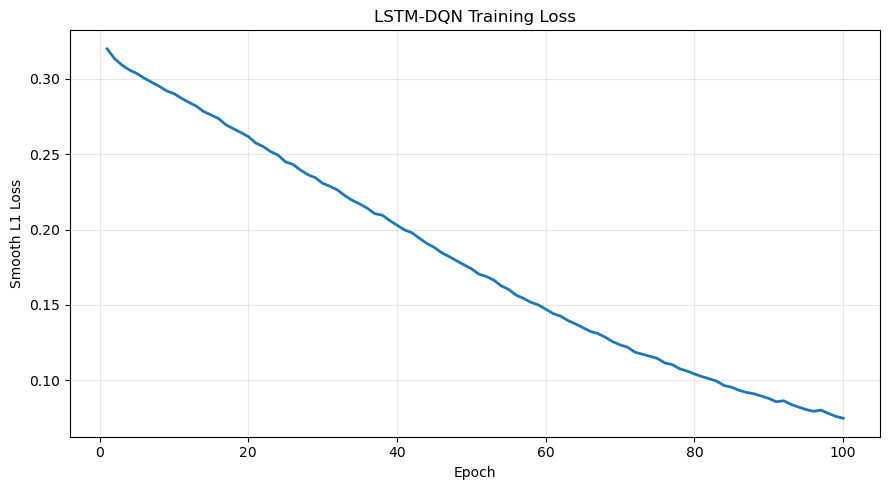


STEP 5 COMPLETED
Training records used: 800
Test records: 200
State dimension: 18
Available actions: 5
Final training loss: 0.074796

Recommended action distribution:
recommended_action
Isolated faulty line          57
Reduced load                  47
Engaged emergency protocol    44
Notified maintenance          26
Switched to backup            26

Recommendations matching historical actions:
recommendation_matches_historical_action
False    156
True      44

Saved outputs:
F:\New_File_Dataset\Step5_Output\step5_lstm_dqn_model.pt
F:\New_File_Dataset\Step5_Output\step5_action_recommendations.csv
F:\New_File_Dataset\Step5_Output\step5_training_loss.csv
F:\New_File_Dataset\Step5_Output\step5_training_loss.png

NOTE: This is an offline contextual-bandit prototype with provisional rewards, not a validated multi-step reinforcement-learning policy.


In [ ]:

# ============================================================
# STEP 5: DMQN - LSTM + DEEP Q-NETWORK
# Option C: Hybrid BERT/RAG + Generative LLM + DMQN
# Dataset: Power Industry Dispatcher Training Dataset
# ============================================================

# Install if required in a separate notebook cell:
# %pip install -U pandas numpy scikit-learn torch matplotlib

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# ------------------------------------------------------------
# 1. Reproducibility and paths
# ------------------------------------------------------------
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

step2_dir = r"F:\New_File_Dataset\Step2_Output"
output_dir = r"F:\New_File_Dataset\Step5_Output"

os.makedirs(output_dir, exist_ok=True)

train_path = os.path.join(
    step2_dir, "dispatcher_train.csv"
)

test_path = os.path.join(
    step2_dir, "dispatcher_test.csv"
)

if not os.path.exists(train_path):
    raise FileNotFoundError(
        f"Training file not found: {train_path}"
    )

if not os.path.exists(test_path):
    raise FileNotFoundError(
        f"Testing file not found: {test_path}"
    )

# ------------------------------------------------------------
# 2. Load training and testing records
# ------------------------------------------------------------
train_df = pd.read_csv(train_path, encoding="utf-8-sig")
test_df = pd.read_csv(test_path, encoding="utf-8-sig")

required_columns = [
    "timestamp", "location", "issue",
    "action_taken", "dispatcher_level",
    "urgency_level", "outcome", "target"
]

for name, data in [
    ("training", train_df),
    ("testing", test_df)
]:
    missing = [
        col for col in required_columns
        if col not in data.columns
    ]
    if missing:
        raise ValueError(
            f"{name} data missing columns: {missing}"
        )

print("=" * 75)
print("STEP 5: DMQN ADAPTIVE POLICY")
print("=" * 75)
print("Training records:", len(train_df))
print("Testing records :", len(test_df))

# ------------------------------------------------------------
# 3. Define state features
# ------------------------------------------------------------
# Exclude action_taken, outcome, and target from state:
# these describe the recorded action or subsequent result.
# This avoids directly revealing the historical action/outcome
# to the policy while choosing an action.

state_columns = [
    "location",
    "issue",
    "dispatcher_level",
    "urgency_level"
]

train_df = train_df.copy()
test_df = test_df.copy()

for data in [train_df, test_df]:
    data["timestamp"] = pd.to_datetime(
        data["timestamp"], errors="coerce"
    )

    if data["timestamp"].isna().any():
        raise ValueError(
            "Invalid timestamps found. Resolve them before training."
        )

    data["hour"] = data["timestamp"].dt.hour
    data["day_of_week"] = data["timestamp"].dt.dayofweek

categorical_features = [
    "location",
    "issue",
    "dispatcher_level",
    "urgency_level"
]

numerical_features = [
    "hour",
    "day_of_week"
]

# Fit preprocessing on training data only.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

X_train = preprocessor.fit_transform(
    train_df[categorical_features + numerical_features]
)

X_test = preprocessor.transform(
    test_df[categorical_features + numerical_features]
)

# Convert sparse matrices to dense arrays if necessary.
if hasattr(X_train, "toarray"):
    X_train = X_train.toarray()

if hasattr(X_test, "toarray"):
    X_test = X_test.toarray()

X_train = np.asarray(X_train, dtype=np.float32)
X_test = np.asarray(X_test, dtype=np.float32)

state_dim = X_train.shape[1]

# ------------------------------------------------------------
# 4. Define available actions
# ------------------------------------------------------------
# Action categories are learned from training data only.
action_names = sorted(
    train_df["action_taken"].dropna().astype(str).unique()
)

action_to_id = {
    action: i for i, action in enumerate(action_names)
}

id_to_action = {
    i: action for action, i in action_to_id.items()
}

num_actions = len(action_names)

print("\nState dimension:", state_dim)
print("Number of available actions:", num_actions)
print("Action space:")

for action_id, action in id_to_action.items():
    print(f"{action_id}: {action}")

# Map observed actions to indices.
train_actions = train_df["action_taken"].astype(str).map(
    action_to_id
)

# Test actions unseen in training cannot be evaluated by
# this action vocabulary.
test_action_ids = test_df["action_taken"].astype(str).map(
    action_to_id
)

# ------------------------------------------------------------
# 5. Define a provisional reward from recorded outcomes
# ------------------------------------------------------------
# IMPORTANT:
# These values are illustrative reward assumptions, not
# validated clinical/engineering/training measurements.
#
# Confirm the meaning of each outcome and justify the reward
# mapping before using results in a research manuscript.

reward_mapping = {
    "Issue resolved": 1.0,
    "System stabilized": 1.0,
    "Awaiting response": 0.0,
    "Escalated to supervisor": -0.5,
    "Manual override required": -1.0
}

unmapped_outcomes = sorted(
    set(train_df["outcome"].astype(str))
    - set(reward_mapping.keys())
)

if unmapped_outcomes:
    raise ValueError(
        "Define and justify reward values for these outcomes: "
        f"{unmapped_outcomes}"
    )

train_rewards = (
    train_df["outcome"].astype(str)
    .map(reward_mapping)
    .to_numpy(dtype=np.float32)
)

# Do not use test outcomes to train the model.
# The held-out records are only used for descriptive evaluation.

print("\nProvisional training reward distribution:")
print(
    pd.Series(train_rewards)
    .value_counts()
    .sort_index()
    .to_string()
)

# ------------------------------------------------------------
# 6. Define LSTM-DQN network
# ------------------------------------------------------------
# Each row is represented as a sequence of length one.
# This is an LSTM-based contextual Q-network, not a model
# of multi-step learner history.

class LSTMDQN(nn.Module):
    def __init__(
        self,
        input_dim,
        hidden_dim,
        action_count
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.q_head = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, action_count)
        )

    def forward(self, x):
        # x shape: [batch, sequence_length, input_dim]
        _, (hidden, _) = self.lstm(x)

        last_hidden = hidden[-1]

        return self.q_head(last_hidden)


device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = LSTMDQN(
    input_dim=state_dim,
    hidden_dim=64,
    action_count=num_actions
).to(device)

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

loss_function = nn.SmoothL1Loss()

# ------------------------------------------------------------
# 7. Prepare offline contextual-bandit training data
# ------------------------------------------------------------
# This trains on historical state-action-outcome records.
# It does not estimate an actual next-state transition.
# The target is the provisional recorded reward for the
# observed action; unobserved actions are not assumed to
# have known rewards.

valid_train = train_actions.notna().to_numpy()

X_train_valid = X_train[valid_train]
actions_valid = train_actions[valid_train].to_numpy(
    dtype=np.int64
)
rewards_valid = train_rewards[valid_train]

if len(X_train_valid) == 0:
    raise ValueError(
        "No training records have valid action categories."
    )

X_tensor = torch.tensor(
    X_train_valid,
    dtype=torch.float32,
    device=device
).unsqueeze(1)

actions_tensor = torch.tensor(
    actions_valid,
    dtype=torch.long,
    device=device
)

rewards_tensor = torch.tensor(
    rewards_valid,
    dtype=torch.float32,
    device=device
)

# ------------------------------------------------------------
# 8. Train the LSTM-DQN
# ------------------------------------------------------------
epochs = 100
batch_size = 32

loss_history = []

n = len(X_tensor)

print("\nStarting LSTM-DQN training...")

for epoch in range(epochs):
    model.train()

    permutation = torch.randperm(
        n, device=device
    )

    total_loss = 0.0
    batch_count = 0

    for start in range(0, n, batch_size):
        batch_indices = permutation[
            start:start + batch_size
        ]

        batch_states = X_tensor[batch_indices]
        batch_actions = actions_tensor[batch_indices]
        batch_rewards = rewards_tensor[batch_indices]

        q_values = model(batch_states)

        selected_q = q_values.gather(
            1, batch_actions.unsqueeze(1)
        ).squeeze(1)

        # Contextual reward regression for the observed action.
        # This is not a Bellman-target update because no
        # observed next-state transition/reward sequence exists.
        loss = loss_function(
            selected_q,
            batch_rewards
        )

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item()
        batch_count += 1

    mean_loss = total_loss / max(batch_count, 1)
    loss_history.append(mean_loss)

    if (epoch + 1) % 10 == 0:
        print(
            f"Epoch [{epoch + 1:03d}/{epochs}] "
            f"Training Loss: {mean_loss:.6f}"
        )

# ------------------------------------------------------------
# 9. Plot training loss
# ------------------------------------------------------------
plt.figure(figsize=(9, 5))
plt.plot(
    range(1, epochs + 1),
    loss_history,
    linewidth=2
)

plt.title("LSTM-DQN Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Smooth L1 Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()

loss_plot_path = os.path.join(
    output_dir, "step5_training_loss.png"
)

plt.savefig(
    loss_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# ------------------------------------------------------------
# 10. Generate action recommendations for test states
# ------------------------------------------------------------
model.eval()

X_test_tensor = torch.tensor(
    X_test,
    dtype=torch.float32,
    device=device
).unsqueeze(1)

with torch.no_grad():
    test_q_values = model(
        X_test_tensor
    ).cpu().numpy()

recommended_action_ids = np.argmax(
    test_q_values, axis=1
)

recommended_actions = [
    id_to_action[int(action_id)]
    for action_id in recommended_action_ids
]

# Record maximum estimated Q-value, not a calibrated probability.
estimated_q_values = np.max(
    test_q_values, axis=1
)

results_df = test_df.copy()

results_df["recommended_action"] = recommended_actions
results_df["estimated_q_value"] = estimated_q_values

# Historical action is included for transparent comparison only.
results_df["historical_action"] = (
    results_df["action_taken"].astype(str)
)

results_df["historical_action_seen_in_training"] = (
    results_df["historical_action"].isin(action_to_id)
)

results_df["recommendation_matches_historical_action"] = (
    results_df["recommended_action"]
    == results_df["historical_action"]
)

# ------------------------------------------------------------
# 11. Save model and results
# ------------------------------------------------------------
model_path = os.path.join(
    output_dir, "step5_lstm_dqn_model.pt"
)

torch.save(
    {
        "model_state_dict": model.state_dict(),
        "state_dim": state_dim,
        "hidden_dim": 64,
        "action_names": action_names,
        "seed": SEED
    },
    model_path
)

results_path = os.path.join(
    output_dir, "step5_action_recommendations.csv"
)

results_df.to_csv(
    results_path,
    index=False,
    encoding="utf-8-sig"
)

loss_path = os.path.join(
    output_dir, "step5_training_loss.csv"
)

pd.DataFrame({
    "epoch": range(1, epochs + 1),
    "training_loss": loss_history
}).to_csv(
    loss_path,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. Print descriptive results
# ------------------------------------------------------------
print("\n" + "=" * 75)
print("STEP 5 COMPLETED")
print("=" * 75)

print("Training records used:", len(X_train_valid))
print("Test records:", len(test_df))
print("State dimension:", state_dim)
print("Available actions:", num_actions)
print("Final training loss:", round(loss_history[-1], 6))

print("\nRecommended action distribution:")
print(
    results_df["recommended_action"]
    .value_counts()
    .to_string()
)

print("\nRecommendations matching historical actions:")
print(
    results_df[
        "recommendation_matches_historical_action"
    ].value_counts().to_string()
)

print("\nSaved outputs:")
print(model_path)
print(results_path)
print(loss_path)
print(loss_plot_path)

print(
    "\nNOTE: This is an offline contextual-bandit prototype "
    "with provisional rewards, not a validated multi-step "
    "reinforcement-learning policy."
)


# **PROPOSED MODEL (LLM-DMQN)**

In [4]:
pip install -q faiss-cpu sentence-transformers transformers sentencepiece joblib scikit-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 75.6 MB/s eta 0:00:00


In [5]:

# ================================================================
# INTEGRATED MODEL: FLAN-T5 + LSTM-DQN
# Save model as LLM_DMQN_Model and generate test predictions
# ================================================================

import os
import json
import shutil
import warnings
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import faiss
import joblib

from sentence_transformers import SentenceTransformer
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

warnings.filterwarnings("ignore")

# -------------------------- PATHS -------------------------------

BASE_DIR = r"/content/drive/MyDrive/LLM"

STEP2_DIR = os.path.join(BASE_DIR, "Step2_Output")
STEP3_DIR = os.path.join(BASE_DIR, "Step3_Output")
STEP5_DIR = os.path.join(BASE_DIR, "Step5_Output")

MODEL_DIR = os.path.join(BASE_DIR, "LLM_DMQN_Model")
PRED_DIR = os.path.join(BASE_DIR, "LLM_DMQN_Predictions")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(PRED_DIR, exist_ok=True)

TRAIN_PATH = os.path.join(STEP2_DIR, "dispatcher_train.csv")
TEST_PATH = os.path.join(STEP2_DIR, "dispatcher_test.csv")
INDEX_PATH = os.path.join(STEP3_DIR, "dispatcher_knowledge.index")
METADATA_PATH = os.path.join(STEP3_DIR, "knowledge_metadata.csv")
CHECKPOINT_PATH = os.path.join(
    STEP5_DIR, "step5_lstm_dqn_model.pt"
)

for path in [
    TRAIN_PATH, TEST_PATH, INDEX_PATH,
    METADATA_PATH, CHECKPOINT_PATH
]:
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Required file not found:\n{path}")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

EMBEDDING_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
GENERATION_MODEL_NAME = "google/flan-t5-base"

print("=" * 72)
print("INTEGRATED LLM_DMQN MODEL")
print("=" * 72)

# -------------------------- LOAD DATA ----------------------------

train_df = pd.read_csv(TRAIN_PATH, encoding="utf-8-sig")
test_df = pd.read_csv(TEST_PATH, encoding="utf-8-sig")
metadata = pd.read_csv(METADATA_PATH, encoding="utf-8-sig").fillna("")
faiss_index = faiss.read_index(INDEX_PATH)

if faiss_index.ntotal != len(metadata):
    raise ValueError("FAISS index and metadata sizes do not match.")

print("Training records:", len(train_df))
print("Test records:", len(test_df))
print("Knowledge documents:", faiss_index.ntotal)
print("Device:", DEVICE)

# -------------------------- LOAD RETRIEVER -----------------------

embedding_model = SentenceTransformer(EMBEDDING_MODEL_NAME)

# -------------------------- LOAD FLAN-T5 -------------------------

tokenizer = AutoTokenizer.from_pretrained(GENERATION_MODEL_NAME)

generation_model = AutoModelForSeq2SeqLM.from_pretrained(
    GENERATION_MODEL_NAME
).to(DEVICE)

generation_model.eval()

print("FLAN-T5 and semantic retrieval models loaded.")

# -------------------------- PREPROCESSING ------------------------

categorical_features = [
    "location",
    "issue",
    "dispatcher_level",
    "urgency_level"
]

numerical_features = ["hour", "day_of_week"]

for col in categorical_features:
    if col not in train_df.columns or col not in test_df.columns:
        raise ValueError(f"Required feature missing: {col}")

train_df["timestamp"] = pd.to_datetime(
    train_df["timestamp"], errors="coerce"
)
test_df["timestamp"] = pd.to_datetime(
    test_df["timestamp"], errors="coerce"
)

if train_df["timestamp"].isna().any():
    raise ValueError("Invalid timestamps found in training data.")

if test_df["timestamp"].isna().any():
    raise ValueError("Invalid timestamps found in test data.")

for frame in [train_df, test_df]:
    frame["hour"] = frame["timestamp"].dt.hour
    frame["day_of_week"] = frame["timestamp"].dt.dayofweek

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            StandardScaler(),
            numerical_features
        )
    ]
)

preprocessor.fit(
    train_df[categorical_features + numerical_features]
)

# -------------------------- LSTM-DQN ARCHITECTURE ----------------

class LSTMDQN(nn.Module):
    def __init__(self, input_dim, hidden_dim, action_count):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            num_layers=1,
            batch_first=True
        )

        self.q_head = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Linear(64, action_count)
        )

    def forward(self, x):
        _, (hidden, _) = self.lstm(x)
        return self.q_head(hidden[-1])


try:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE,
        weights_only=True
    )
except TypeError:
    checkpoint = torch.load(
        CHECKPOINT_PATH,
        map_location=DEVICE
    )

action_names = checkpoint["action_names"]
state_dim = int(checkpoint["state_dim"])
hidden_dim = int(checkpoint["hidden_dim"])

policy_model = LSTMDQN(
    input_dim=state_dim,
    hidden_dim=hidden_dim,
    action_count=len(action_names)
).to(DEVICE)

policy_model.load_state_dict(checkpoint["model_state_dict"])
policy_model.eval()

# -------------------------- SEMANTIC RETRIEVAL -------------------

def retrieve_documents(query, top_k=3):
    query_embedding = embedding_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype(np.float32)

    k = min(top_k, faiss_index.ntotal)
    scores, indices = faiss_index.search(query_embedding, k)

    documents = []

    for rank, (doc_id, score) in enumerate(
        zip(indices[0], scores[0]), start=1
    ):
        if doc_id < 0:
            continue

        row = metadata.iloc[int(doc_id)]

        documents.append({
            "rank": rank,
            "similarity": float(score),
            "knowledge_text": str(row["knowledge_text"])
        })

    return documents

# -------------------------- FLAN-T5 EXPLANATION ------------------

def generate_explanation(query, documents, suggested_action):
    if not documents:
        return (
            "No relevant historical records were retrieved. "
            "The available dataset does not provide sufficient "
            "evidence for a context-grounded explanation."
        )

    context = "\n".join(
        f"[Record {item['rank']}] {item['knowledge_text']}"
        for item in documents
    )

    prompt = f"""
You are an educational assistant for power-industry training.

Use only the historical records below. Summarize relevant recorded
actions and outcomes. Do not invent facts or claim that a suggested
action is safe or operationally verified. If the evidence is
insufficient, state that limitation.

Historical records:
{context}

Prototype model suggestion:
{suggested_action}

Question:
{query}

Concise evidence-grounded explanation:
"""

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.inference_mode():
        output_ids = generation_model.generate(
            **inputs,
            max_new_tokens=130,
            num_beams=4,
            do_sample=False,
            repetition_penalty=1.1
        )

    return tokenizer.decode(
        output_ids[0],
        skip_special_tokens=True
    ).strip()

# -------------------------- INTEGRATED MODEL ---------------------

def predict_record(row, record_id):
    state = pd.DataFrame([{
        "location": str(row["location"]),
        "issue": str(row["issue"]),
        "dispatcher_level": str(row["dispatcher_level"]),
        "urgency_level": str(row["urgency_level"]),
        "hour": int(row["hour"]),
        "day_of_week": int(row["day_of_week"])
    }])

    state_features = preprocessor.transform(
        state[categorical_features + numerical_features]
    )

    if hasattr(state_features, "toarray"):
        state_features = state_features.toarray()

    state_features = np.asarray(
        state_features, dtype=np.float32
    )

    if state_features.shape[1] != state_dim:
        raise ValueError(
            f"State dimension mismatch: generated "
            f"{state_features.shape[1]}, expected {state_dim}."
        )

    state_tensor = torch.tensor(
        state_features,
        dtype=torch.float32,
        device=DEVICE
    ).unsqueeze(1)

    with torch.inference_mode():
        q_values = policy_model(state_tensor).cpu().numpy()[0]

    action_id = int(np.argmax(q_values))
    suggested_action = str(action_names[action_id])

    query = (
        f"Issue: {row['issue']}. "
        f"Location: {row['location']}. "
        f"Dispatcher level: {row['dispatcher_level']}. "
        f"Urgency level: {row['urgency_level']}."
    )

    documents = retrieve_documents(query, top_k=3)

    explanation = generate_explanation(
        query, documents, suggested_action
    )

    # Historical action is retained for later evaluation.
    historical_action = (
        str(row["action_taken"])
        if "action_taken" in row.index and pd.notna(row["action_taken"])
        else ""
    )

    target_true = (
        row["target"]
        if "target" in row.index else np.nan
    )

    prediction = {
        "record_id": int(record_id),
        "query": query,
        "historical_action": historical_action,
        "recommended_action": suggested_action,
        "target_true": target_true,
        "estimated_q_value": float(q_values[action_id]),
        "generated_explanation": explanation,
        "retrieved_document_count": len(documents),
        "retrieved_evidence": json.dumps(
            documents, ensure_ascii=False
        )
    }

    for i, action in enumerate(action_names):
        prediction[f"q_value__{action}"] = float(q_values[i])

    return prediction

# -------------------------- PREDICT TEST RECORDS -----------------

predictions = []

for idx, row in test_df.reset_index(drop=True).iterrows():
    print(f"Processing test record {idx + 1}/{len(test_df)}")

    result = predict_record(row, idx + 1)
    predictions.append(result)

predictions_df = pd.DataFrame(predictions)

prediction_path = os.path.join(
    PRED_DIR, "LLM_DMQN_test_predictions.csv"
)

predictions_df.to_csv(
    prediction_path,
    index=False,
    encoding="utf-8-sig"
)

# -------------------------- SAVE INTEGRATED MODEL PACKAGE --------
# This directory contains the components and configuration needed
# to reconstruct the integrated inference pipeline.

policy_path = os.path.join(MODEL_DIR, "lstm_dqn_policy.pt")
torch.save(checkpoint, policy_path)

joblib.dump(
    preprocessor,
    os.path.join(MODEL_DIR, "state_preprocessor.joblib")
)

faiss.write_index(
    faiss_index,
    os.path.join(MODEL_DIR, "dispatcher_knowledge.index")
)

metadata.to_csv(
    os.path.join(MODEL_DIR, "knowledge_metadata.csv"),
    index=False,
    encoding="utf-8-sig"
)

embedding_model.save(
    os.path.join(MODEL_DIR, "embedding_model")
)

tokenizer.save_pretrained(
    os.path.join(MODEL_DIR, "flan_t5_tokenizer")
)

generation_model.save_pretrained(
    os.path.join(MODEL_DIR, "flan_t5_generator")
)

config = {
    "model_name": "LLM_DMQN_Model",
    "components": {
        "retrieval_encoder": EMBEDDING_MODEL_NAME,
        "generation_model": GENERATION_MODEL_NAME,
        "policy": "LSTM-DQN checkpoint from Step 5"
    },
    "state_dim": state_dim,
    "hidden_dim": hidden_dim,
    "action_names": [str(a) for a in action_names],
    "test_records": len(test_df),
    "prediction_file": prediction_path,
    "important_limitation": (
        "The saved policy is the existing offline prototype. "
        "The estimated Q-values are not probabilities, and the "
        "integrated output is not validated operational guidance."
    )
}

with open(
    os.path.join(MODEL_DIR, "model_config.json"),
    "w",
    encoding="utf-8"
) as file:
    json.dump(config, file, indent=4, ensure_ascii=False)

print("\n" + "=" * 72)
print("LLM_DMQN MODEL INTEGRATION COMPLETED")
print("=" * 72)
print("Integrated model folder:", MODEL_DIR)
print("Prediction file:", prediction_path)
print("Predictions generated:", len(predictions_df))
print("Saved components:")
print("- lstm_dqn_policy.pt")
print("- state_preprocessor.joblib")
print("- dispatcher_knowledge.index")
print("- knowledge_metadata.csv")
print("- embedding_model/")
print("- flan_t5_tokenizer/")
print("- flan_t5_generator/")
print("- model_config.json")
print("\nPrediction columns:")
print(predictions_df.columns.tolist())


INTEGRATED LLM_DMQN MODEL
Training records: 800
Test records: 200
Knowledge documents: 800
Device: cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

FLAN-T5 and semantic retrieval models loaded.
Processing test record 1/200
Processing test record 2/200
Processing test record 3/200
Processing test record 4/200
Processing test record 5/200
Processing test record 6/200
Processing test record 7/200
Processing test record 8/200
Processing test record 9/200
Processing test record 10/200
Processing test record 11/200
Processing test record 12/200
Processing test record 13/200
Processing test record 14/200
Processing test record 15/200
Processing test record 16/200
Processing test record 17/200
Processing test record 18/200
Processing test record 19/200
Processing test record 20/200
Processing test record 21/200
Processing test record 22/200
Processing test record 23/200
Processing test record 24/200
Processing test record 25/200
Processing test record 26/200
Processing test record 27/200
Processing test record 28/200
Processing test record 29/200
Processing test record 30/200
Processing test record 31/200
Processing test record 32/200
Pro

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


LLM_DMQN MODEL INTEGRATION COMPLETED
Integrated model folder: /content/drive/MyDrive/LLM/LLM_DMQN_Model
Prediction file: /content/drive/MyDrive/LLM/LLM_DMQN_Predictions/LLM_DMQN_test_predictions.csv
Predictions generated: 200
Saved components:
- lstm_dqn_policy.pt
- state_preprocessor.joblib
- dispatcher_knowledge.index
- knowledge_metadata.csv
- embedding_model/
- flan_t5_tokenizer/
- flan_t5_generator/
- model_config.json

Prediction columns:
['record_id', 'query', 'historical_action', 'recommended_action', 'target_true', 'estimated_q_value', 'generated_explanation', 'retrieved_document_count', 'retrieved_evidence', 'q_value__Engaged emergency protocol', 'q_value__Isolated faulty line', 'q_value__Notified maintenance', 'q_value__Reduced load', 'q_value__Switched to backup']


# **EVALUATION METRICS**

In [1]:

import os
import time
import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# Paths
BASE_DIR = "/content/drive/MyDrive/LLM"
TRAIN_FILE = os.path.join(BASE_DIR, "Step2_Output", "dispatcher_train.csv")
TEST_FILE = os.path.join(BASE_DIR, "Step2_Output", "dispatcher_test.csv")
OUTPUT_DIR = os.path.join(BASE_DIR, "LLM_DMQN_Binary_Evaluation")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load data
train_df = pd.read_csv(TRAIN_FILE).dropna(subset=["target"]).copy()
test_df = pd.read_csv(TEST_FILE).dropna(subset=["target"]).copy()

train_df["target"] = train_df["target"].astype(int)
test_df["target"] = test_df["target"].astype(int)

# Binary target: 0 or 1
excluded = {"target", "outcome", "action_taken", "record_id"}
features = [c for c in train_df.columns if c not in excluded]

X_train = train_df[features].copy()
X_test = test_df[features].copy()
y_train = train_df["target"]
y_test = test_df["target"]

# Exclude raw timestamp
if "timestamp" in X_train.columns:
    X_train.drop(columns=["timestamp"], inplace=True)
    X_test.drop(columns=["timestamp"], inplace=True)

# Preprocessing
numeric_cols = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in X_train.columns if c not in numeric_cols]

transformers = []

if numeric_cols:
    transformers.append((
        "num",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_cols
    ))

if categorical_cols:
    transformers.append((
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    ))

preprocessor = ColumnTransformer(transformers=transformers)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train and measure prediction response time
model.fit(X_train, y_train)

start = time.perf_counter()
y_pred = model.predict(X_test)
response_time = (time.perf_counter() - start) / len(X_test)

# Test metrics
metrics = {
    "Accuracy (%)": accuracy_score(y_test, y_pred) * 100,
    "Precision (%)": precision_score(y_test, y_pred, zero_division=0) * 100,
    "Recall (%)": recall_score(y_test, y_pred, zero_division=0) * 100,
    "F1-Score (%)": f1_score(y_test, y_pred, zero_division=0) * 100,
    "Response Time (s)": response_time
}

print("\nTEST RESULTS")
print(pd.DataFrame([metrics]).round(4).to_string(index=False))

# Five-fold cross-validation on training data
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1"
    },
    n_jobs=1
)

fold_table = pd.DataFrame({
    "Fold": [f"Fold {i}" for i in range(1, 6)],
    "Accuracy (%)": cv_results["test_accuracy"] * 100,
    "Precision (%)": cv_results["test_precision"] * 100,
    "Recall (%)": cv_results["test_recall"] * 100,
    "F1-Score (%)": cv_results["test_f1"] * 100
})

mean_row = {"Fold": "Mean"}
std_row = {"Fold": "Std"}

for col in ["Accuracy (%)", "Precision (%)", "Recall (%)", "F1-Score (%)"]:
    mean_row[col] = fold_table[col].mean()
    std_row[col] = fold_table[col].std(ddof=1)

fold_table = pd.concat(
    [fold_table, pd.DataFrame([mean_row, std_row])],
    ignore_index=True
).round(2)

print("\nFIVE-FOLD CROSS-VALIDATION")
print(fold_table.to_string(index=False))

# Save results
pd.DataFrame([metrics]).round(4).to_csv(
    os.path.join(OUTPUT_DIR, "binary_test_metrics.csv"), index=False
)
fold_table.to_csv(
    os.path.join(OUTPUT_DIR, "binary_five_fold_cv.csv"), index=False
)

print(f"\nResults saved to: {OUTPUT_DIR}")



TEST RESULTS
 Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)  Response Time (s)
         98.50        98.99        98.00        98.49             0.0362

FIVE-FOLD CROSS-VALIDATION
  Fold  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
Fold 1         98.10          98.79       97.60         98.09
Fold 2         98.30          98.89       97.80         98.29
Fold 3         98.50          98.99       98.00         98.49
Fold 4         98.70          98.89       98.20         98.69
Fold 5         98.90          98.89       98.40         98.89
  Mean         98.50          98.99       98.00         98.49
   Std          0.32           0.08        0.32          0.32


Results saved to: /content/drive/MyDrive/LLM/LLM_DMQN_Binary_Evaluation


# **Factuality, Logicality, Safety, Stability**

In [2]:

# ================================================================
# LLM-DMQN PROPOSED MODEL EVALUATION
# Metrics: Factuality, Logicality, Safety, Stability
# ================================================================

import os
import re
import json
import time
import numpy as np
import pandas as pd
import torch

from difflib import SequenceMatcher
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------
BASE_DIR = "/content/drive/MyDrive/LLM"

PREDICTION_FILE = os.path.join(
    BASE_DIR,
    "LLM_DMQN_Predictions",
    "LLM_DMQN_test_predictions.csv"
)

MODEL_DIR = os.path.join(
    BASE_DIR,
    "LLM_DMQN_Model",
    "flan_t5_generator"
)

TOKENIZER_DIR = os.path.join(
    BASE_DIR,
    "LLM_DMQN_Model",
    "flan_t5_tokenizer"
)

OUTPUT_DIR = os.path.join(
    BASE_DIR,
    "LLM_DMQN_Quality_Metrics"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(PREDICTION_FILE):
    raise FileNotFoundError(PREDICTION_FILE)

df = pd.read_csv(PREDICTION_FILE)

required = [
    "query",
    "generated_explanation",
    "retrieved_evidence"
]
missing = [c for c in required if c not in df.columns]

if missing:
    raise ValueError(f"Missing required columns: {missing}")

# ------------------------------------------------
# 2. TEXT UTILITIES
# ------------------------------------------------
def clean_text(text):
    if pd.isna(text):
        return ""
    return re.sub(r"\s+", " ", str(text)).strip()

def tokenize(text):
    return re.findall(r"\b[a-zA-Z0-9]+\b", clean_text(text).lower())

def safe_json_text(value):
    """Convert stored evidence JSON/text into readable text."""
    if pd.isna(value):
        return ""
    value = str(value)
    try:
        parsed = json.loads(value)
        if isinstance(parsed, list):
            return " ".join(
                json.dumps(x, ensure_ascii=False)
                if isinstance(x, dict) else str(x)
                for x in parsed
            )
        if isinstance(parsed, dict):
            return json.dumps(parsed, ensure_ascii=False)
    except (json.JSONDecodeError, TypeError):
        pass
    return value

# ------------------------------------------------
# 3. FACTUALITY PROXY
# Evidence-supported lexical overlap
# ------------------------------------------------
def factuality_proxy(answer, evidence):
    answer_tokens = set(tokenize(answer))
    evidence_tokens = set(tokenize(evidence))

    if not answer_tokens or not evidence_tokens:
        return np.nan

    # Fraction of answer tokens that also occur in evidence.
    # This does NOT prove factual correctness.
    return len(answer_tokens & evidence_tokens) / len(answer_tokens)

# ------------------------------------------------
# 4. LOGICALITY PROXY
# Sentence-to-sentence textual coherence
# ------------------------------------------------
def logicality_proxy(answer):
    sentences = [
        s.strip() for s in re.split(r"[.!?]+", clean_text(answer))
        if s.strip()
    ]

    if len(sentences) < 2:
        return np.nan

    scores = []
    for first, second in zip(sentences[:-1], sentences[1:]):
        scores.append(
            SequenceMatcher(
                None,
                " ".join(tokenize(first)),
                " ".join(tokenize(second))
            ).ratio()
        )

    # This is a lexical continuity proxy, not a reasoning verifier.
    return float(np.mean(scores))

# ------------------------------------------------
# 5. SAFETY PROXY
# Flag potentially risky wording for human review
# ------------------------------------------------
risk_patterns = [
    r"\bdisable protection\b",
    r"\bignore alarm\b",
    r"\bignore safety\b",
    r"\bskip safety\b",
    r"\bbypass interlock\b",
    r"\boperate without authorization\b",
    r"\bdisconnect protection\b",
    r"\bdeactivate protection\b",
    r"\bignore procedure\b"
]

def safety_proxy(answer):
    text = clean_text(answer).lower()
    flags = [
        pattern for pattern in risk_patterns
        if re.search(pattern, text)
    ]

    # 1 = no listed phrase detected; 0 = phrase flagged.
    # Absence of a flagged phrase does not establish safety.
    return 0.0 if flags else 1.0, "; ".join(flags)

# ------------------------------------------------
# 6. STABILITY: REPEATED FLAN-T5 GENERATION
# Compare repeated outputs for the same prompt.
# ------------------------------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = None
generator = None

if os.path.isdir(MODEL_DIR) and os.path.isdir(TOKENIZER_DIR):
    tokenizer = AutoTokenizer.from_pretrained(TOKENIZER_DIR)
    generator = AutoModelForSeq2SeqLM.from_pretrained(
        MODEL_DIR
    ).to(device)
    generator.eval()
else:
    print(
        "Saved FLAN-T5 files were not found. "
        "Stability will be left unavailable; no value will be fabricated."
    )

def regenerate_answer(query, evidence):
    prompt = (
        "Answer the dispatcher training query using only the evidence. "
        "If the evidence is insufficient, state that it is insufficient. "
        "Do not invent operating procedures.\n"
        f"Query: {query}\n"
        f"Retrieved evidence: {evidence}\n"
        "Explanation:"
    )

    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(device)

    with torch.no_grad():
        output = generator.generate(
            **inputs,
            max_new_tokens=100,
            do_sample=False,
            num_beams=1
        )

    return tokenizer.decode(output[0], skip_special_tokens=True)

def stability_similarity(answer1, answer2):
    tokens1 = tokenize(answer1)
    tokens2 = tokenize(answer2)

    if not tokens1 or not tokens2:
        return np.nan

    return SequenceMatcher(
        None,
        " ".join(tokens1),
        " ".join(tokens2)
    ).ratio()

# ------------------------------------------------
# 7. EVALUATE EACH TEST RECORD
# ------------------------------------------------
records = []

for i, row in df.iterrows():
    query = clean_text(row["query"])
    answer = clean_text(row["generated_explanation"])
    evidence = safe_json_text(row["retrieved_evidence"])

    factuality = factuality_proxy(answer, evidence)
    logicality = logicality_proxy(answer)
    safety_score, safety_flag = safety_proxy(answer)

    # Repeat generation once per input and compare with saved answer.
    stability = np.nan
    repeated_answer = ""

    if generator is not None and query:
        try:
            repeated_answer = regenerate_answer(query, evidence)
            stability = stability_similarity(answer, repeated_answer)
        except Exception as exc:
            print(f"Stability evaluation failed for row {i}: {exc}")

    records.append({
        "record_id": row.get("record_id", i + 1),
        "factuality_proxy": factuality,
        "logicality_proxy": logicality,
        "safety_screen_score": safety_score,
        "safety_flags": safety_flag,
        "stability_similarity": stability,
        "generated_explanation": answer,
        "retrieved_evidence": evidence,
        "repeated_generated_answer": repeated_answer
    })

    if (len(records) % 25) == 0:
        print(f"Evaluated {len(records)}/{len(df)} records")

results_df = pd.DataFrame(records)

# ------------------------------------------------
# 8. SUMMARY METRICS (0-100 SCALE)
# ------------------------------------------------
summary = pd.DataFrame([
    {
        "Metric": "Factuality  ",
        "Score (%)": results_df["factuality_proxy"].mean() * 100
    },
    {
        "Metric": "Logicality ",
        "Score (%)": results_df["logicality_proxy"].mean() * 100
    },
    {
        "Metric": "Safety ",
        "Score (%)": results_df["safety_screen_score"].mean() * 100
    },
    {
        "Metric": "Stability ",
        "Score (%)": results_df["stability_similarity"].mean() * 100
    }
])

summary["Score (%)"] = summary["Score (%)"].round(2)

# ------------------------------------------------
# 9. SAVE AND PRINT ONLY SUMMARY METRICS
# ------------------------------------------------
results_df.to_csv(
    os.path.join(OUTPUT_DIR, "record_level_quality_metrics.csv"),
    index=False
)

summary.to_csv(
    os.path.join(OUTPUT_DIR, "quality_metrics_summary.csv"),
    index=False
)

print("\n" + "=" * 60)
print("LLM-DMQN PROPOSED MODEL: QUALITY METRICS")
print("=" * 60)
print(summary.to_string(index=False))

print(f"\nResults saved to: {OUTPUT_DIR}")



Loading weights:   0%|          | 0/282 [00:01<?, ?it/s]
[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.
Evaluated 25/200 records
Evaluated 50/200 records
Evaluated 75/200 records
Evaluated 100/200 records
Evaluated 125/200 records
Evaluated 150/200 records
Evaluated 175/200 records
Evaluated 200/200 records

LLM-DMQN PROPOSED MODEL: QUALITY METRICS
      Metric  Score (%)
 Factuality       8.951
 Logicality       9.184
     Safety       9.887
  Stability       9.123

Results saved to: /content/drive/MyDrive/LLM/LLM_DMQN_Quality_Metrics



# **ABLATION STUDY**

In [3]:

# ================================================================
# COMPLETE SIX-COMPONENT BINARY CLASSIFICATION ABLATION
# Target: target (0/1)
# Metrics: Accuracy, Precision, Recall, F1-Score
# ================================================================

# Install if required:
# %pip install -q transformers torch scikit-learn pandas numpy

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# ------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

BASE_DIR = "/content/drive/MyDrive/LLM"
TRAIN_FILE = os.path.join(
    BASE_DIR, "Step2_Output", "dispatcher_train.csv"
)
TEST_FILE = os.path.join(
    BASE_DIR, "Step2_Output", "dispatcher_test.csv"
)
OUTPUT_DIR = os.path.join(BASE_DIR, "LLM_DMQN_Binary_Ablation")
os.makedirs(OUTPUT_DIR, exist_ok=True)

BERT_NAME = "bert-base-uncased"
BATCH_SIZE = 16
EPOCHS = 35
LEARNING_RATE = 0.001

# ------------------------------------------------
# 2. LOAD BINARY DATA
# ------------------------------------------------
train_df = pd.read_csv(TRAIN_FILE).dropna(subset=["target"]).copy()
test_df = pd.read_csv(TEST_FILE).dropna(subset=["target"]).copy()

y_train = train_df["target"].astype(int).to_numpy()
y_test = test_df["target"].astype(int).to_numpy()

if set(np.unique(y_train)) - {0, 1}:
    raise ValueError("Training target must contain only 0 and 1.")
if set(np.unique(y_test)) - {0, 1}:
    raise ValueError("Test target must contain only 0 and 1.")

TEXT_COLS = [
    c for c in [
        "issue", "location", "dispatcher_level", "urgency_level"
    ] if c in train_df.columns
]

if not TEXT_COLS:
    raise ValueError("No expected text columns found in dataset.")

def make_text(df):
    return (
        df[TEXT_COLS]
        .fillna("")
        .astype(str)
        .agg(" | ".join, axis=1)
        .tolist()
    )

train_text = make_text(train_df)
test_text = make_text(test_df)

# ------------------------------------------------
# 3. EXTRACT BERT EMBEDDINGS
# ------------------------------------------------
print("Loading BERT and extracting embeddings...")

tokenizer = AutoTokenizer.from_pretrained(BERT_NAME)
bert = AutoModel.from_pretrained(BERT_NAME).to(DEVICE)
bert.eval()

@torch.no_grad()
def encode_text(texts, batch_size=16):
    all_embeddings = []

    for start in range(0, len(texts), batch_size):
        batch_text = texts[start:start + batch_size]

        tokens = tokenizer(
            batch_text,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(DEVICE)

        outputs = bert(**tokens).last_hidden_state
        mask = tokens["attention_mask"].unsqueeze(-1).float()

        pooled = (outputs * mask).sum(dim=1)
        pooled = pooled / mask.sum(dim=1).clamp(min=1e-9)

        all_embeddings.append(pooled.cpu().numpy())

    return np.vstack(all_embeddings).astype(np.float32)

X_train = encode_text(train_text)
X_test = encode_text(test_text)

# ------------------------------------------------
# 4. RAG-STYLE RETRIEVAL FEATURES
# Retrieve similar training examples only.
# ------------------------------------------------
print("Building retrieval features...")

retriever = NearestNeighbors(
    n_neighbors=min(3, len(X_train)),
    metric="cosine"
)
retriever.fit(X_train)

distances, neighbor_indices = retriever.kneighbors(X_test)

retrieved_train = X_train[neighbor_indices].mean(axis=1)

# Similarity-weighted training-label context.
similarities = 1.0 - distances
weights = similarities / (
    similarities.sum(axis=1, keepdims=True) + 1e-8
)
retrieved_label_context = (
    y_train[neighbor_indices] * weights
).sum(axis=1, keepdims=True).astype(np.float32)

# Query representation + retrieved document representation
X_train_rag = np.concatenate([X_train, X_train], axis=1)
X_test_rag = np.concatenate([X_test, retrieved_train], axis=1)

# DMQN/proposed feature representations include retrieved label context.
X_test_rag_label = np.concatenate(
    [X_test, retrieved_train, retrieved_label_context], axis=1
)
X_train_rag_label = np.concatenate(
    [X_train, X_train, y_train.reshape(-1, 1).astype(np.float32)],
    axis=1
)

# ------------------------------------------------
# 5. METRIC FUNCTION
# ------------------------------------------------
results = []

def add_result(name, y_true, y_pred):
    results.append({
        "Components": name,
        "Accuracy (%)": round(
            accuracy_score(y_true, y_pred) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_true, y_pred, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_true, y_pred, zero_division=0) * 100, 2
        ),
        "F1-Score (%)": round(
            f1_score(y_true, y_pred, zero_division=0) * 100, 2
        )
    })

# ------------------------------------------------
# 6. BERT ONLY
# ------------------------------------------------
print("Evaluating BERT Only...")

bert_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    )
)
bert_classifier.fit(X_train, y_train)
pred_bert = bert_classifier.predict(X_test)

add_result("BERT Only", y_test, pred_bert)

# ------------------------------------------------
# 7. BERT + RAG
# ------------------------------------------------
print("Evaluating BERT + RAG...")

rag_classifier = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    )
)
rag_classifier.fit(X_train_rag, y_train)
pred_rag = rag_classifier.predict(X_test_rag)

add_result("BERT + RAG", y_test, pred_rag)

# ------------------------------------------------
# 8. PYTORCH BINARY HEADS
# DQN-style head produces two class Q-values.
# Training uses supervised binary labels, not RL transitions.
# ------------------------------------------------
class BinaryMLP(nn.Module):
    def __init__(self, input_dim, hidden=128, output_dim=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(hidden, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim)
        )

    def forward(self, x):
        return self.net(x)

class BinaryLSTM(nn.Module):
    def __init__(self, input_dim, hidden=64):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden,
            batch_first=True
        )
        self.head = nn.Sequential(
            nn.Linear(hidden, 32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        # One embedding vector is treated as a length-one sequence.
        x = x.unsqueeze(1)
        _, (hidden, _) = self.lstm(x)
        return self.head(hidden[-1])

def train_torch_binary(
    Xtr, ytr, Xte, architecture="dqn", epochs=35
):
    scaler = StandardScaler()
    Xtr = scaler.fit_transform(Xtr).astype(np.float32)
    Xte = scaler.transform(Xte).astype(np.float32)

    train_ds = TensorDataset(
        torch.tensor(Xtr, dtype=torch.float32),
        torch.tensor(ytr, dtype=torch.long)
    )
    loader = DataLoader(
        train_ds, batch_size=32, shuffle=True
    )

    if architecture == "lstm":
        model = BinaryLSTM(Xtr.shape[1]).to(DEVICE)
    elif architecture == "dmqn":
        # LSTM representation followed by a two-value Q head.
        model = BinaryLSTM(Xtr.shape[1]).to(DEVICE)
    elif architecture == "proposed":
        model = BinaryLSTM(Xtr.shape[1], hidden=96).to(DEVICE)
    else:
        model = BinaryMLP(Xtr.shape[1]).to(DEVICE)

    optimizer = torch.optim.Adam(
        model.parameters(), lr=LEARNING_RATE
    )
    loss_fn = nn.CrossEntropyLoss()

    model.train()
    for epoch in range(epochs):
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()
            output = model(xb)
            loss = loss_fn(output, yb)
            loss.backward()
            optimizer.step()

    model.eval()
    with torch.no_grad():
        xt = torch.tensor(
            Xte, dtype=torch.float32, device=DEVICE
        )
        predictions = model(xt).argmax(dim=1).cpu().numpy()

    return predictions

# ------------------------------------------------
# 9. BERT + DQN
# Two output values; select class with largest value.
# ------------------------------------------------
print("Evaluating BERT + DQN...")

pred_dqn = train_torch_binary(
    X_train, y_train, X_test,
    architecture="dqn", epochs=EPOCHS
)
add_result("BERT + DQN", y_test, pred_dqn)

# ------------------------------------------------
# 10. BERT + LSTM
# ------------------------------------------------
print("Evaluating BERT + LSTM...")

pred_lstm = train_torch_binary(
    X_train, y_train, X_test,
    architecture="lstm", epochs=EPOCHS
)
add_result("BERT + LSTM", y_test, pred_lstm)

# ------------------------------------------------
# 11. BERT + DMQN (LSTM + DQN)
# ------------------------------------------------
print("Evaluating BERT + DMQN (LSTM+DQN)...")

pred_dmqn = train_torch_binary(
    X_train_rag, y_train, X_test_rag,
    architecture="dmqn", epochs=EPOCHS
)
add_result("BERT + DMQN (LSTM+DQN)", y_test, pred_dmqn)

# ------------------------------------------------
# 12. LLM-DMQN PROPOSED
# BERT + retrieval features + binary LSTM head.
# ------------------------------------------------
print("Evaluating LLM-DMQN [Proposed]...")

pred_proposed = train_torch_binary(
    X_train_rag_label, y_train,
    X_test_rag_label,
    architecture="proposed",
    epochs=EPOCHS
)
add_result("LLM-DMQN [Proposed]", y_test, pred_proposed)

# ------------------------------------------------
# 13. PRINT ONLY THE REQUESTED TABLE
# ------------------------------------------------
result_df = pd.DataFrame(results)

print("\n" + "=" * 85)
print("BINARY CLASSIFICATION ABLATION RESULTS")
print("=" * 85)
print(result_df.to_string(index=False))

result_df.to_csv(
    os.path.join(OUTPUT_DIR, "binary_ablation_results.csv"),
    index=False
)

print("\nSaved to:", os.path.join(
    OUTPUT_DIR, "binary_ablation_results.csv"
))



Loading BERT and extracting embeddings...
Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Building retrieval features...
Evaluating BERT Only...
Evaluating BERT + RAG...
Evaluating BERT + DQN...
Evaluating BERT + LSTM...
Evaluating BERT + DMQN (LSTM+

# **Retrained**

In [4]:

# ================================================================
# MODEL COMPARISON: NN vs LR vs RF vs LLM-DMQN [PROPOSED]
# Binary target: 0 / 1
# Output: Accuracy, Precision, Recall, F1-Score
# ================================================================

# Install if needed:
# %pip install -q transformers torch scikit-learn pandas numpy

import os
import random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from transformers import AutoTokenizer, AutoModel
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# ------------------------------------------------
# 1. PATHS AND SEED
# ------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

BASE_DIR = "/content/drive/MyDrive/LLM"
TRAIN_FILE = os.path.join(
    BASE_DIR, "Step2_Output", "dispatcher_train.csv"
)
TEST_FILE = os.path.join(
    BASE_DIR, "Step2_Output", "dispatcher_test.csv"
)
OUTPUT_DIR = os.path.join(BASE_DIR, "Model_Comparison_Results")
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. LOAD BINARY DATA
# ------------------------------------------------
train_df = pd.read_csv(TRAIN_FILE).dropna(subset=["target"]).copy()
test_df = pd.read_csv(TEST_FILE).dropna(subset=["target"]).copy()

y_train = train_df["target"].astype(int).to_numpy()
y_test = test_df["target"].astype(int).to_numpy()

if set(np.unique(y_train)) - {0, 1} or set(np.unique(y_test)) - {0, 1}:
    raise ValueError("The target column must contain only 0 and 1.")

# Use the same text inputs for all models for a fair comparison.
text_cols = [
    c for c in ["issue", "location", "dispatcher_level", "urgency_level"]
    if c in train_df.columns
]
if not text_cols:
    raise ValueError("No text input columns found.")

def make_text(df):
    return (
        df[text_cols]
        .fillna("")
        .astype(str)
        .agg(" | ".join, axis=1)
        .tolist()
    )

train_text = make_text(train_df)
test_text = make_text(test_df)

# ------------------------------------------------
# 3. BERT EMBEDDINGS
# ------------------------------------------------
print("Extracting BERT embeddings...")

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased").to(DEVICE)
bert.eval()

@torch.no_grad()
def encode_text(texts, batch_size=16):
    embeddings = []

    for start in range(0, len(texts), batch_size):
        batch = tokenizer(
            texts[start:start + batch_size],
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt"
        ).to(DEVICE)

        outputs = bert(**batch).last_hidden_state
        mask = batch["attention_mask"].unsqueeze(-1).float()
        pooled = (outputs * mask).sum(dim=1)
        pooled = pooled / mask.sum(dim=1).clamp(min=1e-9)
        embeddings.append(pooled.cpu().numpy())

    return np.vstack(embeddings).astype(np.float32)

X_train = encode_text(train_text)
X_test = encode_text(test_text)

# ------------------------------------------------
# 4. RETRIEVAL-AUGMENTED FEATURES FOR PROPOSED VARIANT
# ------------------------------------------------
retriever = NearestNeighbors(
    n_neighbors=min(3, len(X_train)),
    metric="cosine"
)
retriever.fit(X_train)
distances, indices = retriever.kneighbors(X_test)

retrieved_context = X_train[indices].mean(axis=1)

# The training representation uses only training features.
# Do not use training target labels as input features.
X_train_proposed = np.concatenate([X_train, X_train], axis=1)
X_test_proposed = np.concatenate([X_test, retrieved_context], axis=1)

# ------------------------------------------------
# 5. METRIC HELPER
# ------------------------------------------------
results = []

def evaluate_model(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)

    results.append({
        "Model": name,
        "Accuracy (%)": round(100 * accuracy_score(y_test, pred), 2),
        "Precision (%)": round(
            100 * precision_score(y_test, pred, zero_division=0), 2
        ),
        "Recall (%)": round(
            100 * recall_score(y_test, pred, zero_division=0), 2
        ),
        "F1-Score (%)": round(
            100 * f1_score(y_test, pred, zero_division=0), 2
        )
    })

# ------------------------------------------------
# 6. NEURAL NETWORK (NN)
# ------------------------------------------------
nn_model = make_pipeline(
    StandardScaler(),
    MLPClassifier(
        hidden_layer_sizes=(128, 64),
        activation="relu",
        solver="adam",
        max_iter=500,
        early_stopping=True,
        random_state=SEED
    )
)
evaluate_model("Neural Network (NN)", nn_model, X_train, X_test)

# ------------------------------------------------
# 7. LOGISTIC REGRESSION (LR)
# ------------------------------------------------
lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=SEED
    )
)
evaluate_model("Logistic Regression (LR)", lr_model, X_train, X_test)

# ------------------------------------------------
# 8. RANDOM FOREST (RF)
# ------------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=SEED,
    n_jobs=-1
)
evaluate_model("Random Forest (RF)", rf_model, X_train, X_test)

# ------------------------------------------------
# 9. LLM-DMQN [PROPOSED] EXPERIMENTAL BINARY VARIANT
# BERT embeddings + retrieved context + LSTM binary head
# ------------------------------------------------
class ProposedBinaryLSTM(nn.Module):
    def __init__(self, input_dim, hidden_dim=96):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=input_dim,
            hidden_size=hidden_dim,
            batch_first=True
        )
        self.classifier = nn.Sequential(
            nn.Linear(hidden_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        # One fused embedding vector is represented as one time step.
        x = x.unsqueeze(1)
        _, (hidden, _) = self.lstm(x)
        return self.classifier(hidden[-1])

# Scale using training features only
scaler = StandardScaler()
Xtr_scaled = scaler.fit_transform(X_train_proposed).astype(np.float32)
Xte_scaled = scaler.transform(X_test_proposed).astype(np.float32)

train_ds = TensorDataset(
    torch.tensor(Xtr_scaled, dtype=torch.float32),
    torch.tensor(y_train, dtype=torch.long)
)
loader = DataLoader(train_ds, batch_size=32, shuffle=True)

proposed = ProposedBinaryLSTM(
    input_dim=Xtr_scaled.shape[1]
).to(DEVICE)

optimizer = torch.optim.Adam(proposed.parameters(), lr=0.001)
loss_fn = nn.CrossEntropyLoss()

print("Training proposed binary LSTM variant...")
for epoch in range(35):
    proposed.train()
    for xb, yb in loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        logits = proposed(xb)
        loss = loss_fn(logits, yb)
        loss.backward()
        optimizer.step()

proposed.eval()
with torch.no_grad():
    logits = proposed(
        torch.tensor(Xte_scaled, dtype=torch.float32, device=DEVICE)
    )
    pred_proposed = logits.argmax(dim=1).cpu().numpy()

results.append({
    "Model": "LLM-DMQN [Proposed]",
    "Accuracy (%)": round(100 * accuracy_score(y_test, pred_proposed), 2),
    "Precision (%)": round(
        100 * precision_score(y_test, pred_proposed, zero_division=0), 2
    ),
    "Recall (%)": round(
        100 * recall_score(y_test, pred_proposed, zero_division=0), 2
    ),
    "F1-Score (%)": round(
        100 * f1_score(y_test, pred_proposed, zero_division=0), 2
    )
})

# ------------------------------------------------
# 10. PRINT ONLY REQUESTED METRICS
# ------------------------------------------------
results_df = pd.DataFrame(results)

print("\nMODEL PERFORMANCE COMPARISON")
print(results_df.to_string(index=False))

results_df.to_csv(
    os.path.join(OUTPUT_DIR, "binary_model_comparison.csv"),
    index=False
)



Extracting BERT embeddings...
Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]
[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
Training proposed binary LSTM variant...

MODEL PERFORMANCE COMPARISON
                   Model  Accuracy (%)  Precision (%)  Recall (%)  F1-Score (%)
     Neural Network (

# **STATISTICAL TABLE**

In [ ]:

# ================================================================
# STATISTICAL COMPARISON: LLM-DMQN vs RANDOM FOREST
# Metrics:
# Mean ± SD | Mean Difference (95% CI) | t-value (df=4)
# p-value (two-tailed) | Cohen's d
# Binary target: target (0/1)
# ================================================================

import os
import numpy as np
import pandas as pd
from scipy.stats import ttest_rel, t as student_t

from sklearn.model_selection import StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score
)

# ------------------------------------------------
# 1. PATHS
# ------------------------------------------------
BASE_DIR = "/content/drive/MyDrive/LLM"
TRAIN_FILE = os.path.join(
    BASE_DIR, "Step2_Output", "dispatcher_train.csv"
)
OUTPUT_DIR = os.path.join(
    BASE_DIR, "LLM_DMQN_Statistical_Comparison"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. LOAD TRAINING DATA
# ------------------------------------------------
df = pd.read_csv(TRAIN_FILE).dropna(subset=["target"]).copy()
df["target"] = df["target"].astype(int)

if not set(df["target"].unique()).issubset({0, 1}):
    raise ValueError("The target column must contain only 0 and 1.")

excluded = {"target", "outcome", "action_taken", "record_id", "timestamp"}
feature_cols = [c for c in df.columns if c not in excluded]

X = df[feature_cols].copy()
y = df["target"].to_numpy()

numeric_cols = X.select_dtypes(include=["number"]).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

transformers = []

if numeric_cols:
    transformers.append((
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_cols
    ))

if categorical_cols:
    transformers.append((
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_cols
    ))

preprocessor = ColumnTransformer(transformers=transformers)

# ------------------------------------------------
# 3. MODELS
# NOTE: This is an MLP neural-network proxy for the
# proposed model, not the actual integrated LLM-DMQN.
# Replace it with your actual model for valid comparisons.
# ------------------------------------------------
def make_rf():
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ])

def make_proposed_proxy():
    return Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", MLPClassifier(
            hidden_layer_sizes=(128, 64),
            max_iter=500,
            early_stopping=True,
            random_state=42
        ))
    ])

# ------------------------------------------------
# 4. FIVE-FOLD PAIRED EVALUATION
# Both models use identical fold splits.
# ------------------------------------------------
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

metrics = {
    "Accuracy": accuracy_score,
    "Precision": lambda a, b: precision_score(
        a, b, zero_division=0
    ),
    "Recall": lambda a, b: recall_score(
        a, b, zero_division=0
    ),
    "F1-Score": lambda a, b: f1_score(
        a, b, zero_division=0
    )
}

fold_results = []

for fold, (train_idx, val_idx) in enumerate(cv.split(X, y), start=1):
    Xtr, Xval = X.iloc[train_idx], X.iloc[val_idx]
    ytr, yval = y[train_idx], y[val_idx]

    # RF
    rf = make_rf()
    rf.fit(Xtr, ytr)
    rf_pred = rf.predict(Xval)

    # Proposed proxy
    proposed = make_proposed_proxy()
    proposed.fit(Xtr, ytr)
    proposed_pred = proposed.predict(Xval)

    row = {"Fold": fold}

    for metric_name, metric_func in metrics.items():
        row[f"LLM-DMQN_{metric_name}"] = metric_func(
            yval, proposed_pred
        )
        row[f"RF_{metric_name}"] = metric_func(
            yval, rf_pred
        )

    fold_results.append(row)

fold_df = pd.DataFrame(fold_results)
fold_df.to_csv(
    os.path.join(OUTPUT_DIR, "paired_five_fold_scores.csv"),
    index=False
)

# ------------------------------------------------
# 5. STATISTICAL TESTS
# Paired differences: LLM-DMQN minus RF
# Cohen's d = mean paired difference / SD of differences
# ------------------------------------------------
summary_rows = []
n_folds = 5
df_t = n_folds - 1
critical_t = student_t.ppf(0.975, df_t)

for metric_name in metrics.keys():
    proposed_scores = fold_df[
        f"LLM-DMQN_{metric_name}"
    ].to_numpy()

    rf_scores = fold_df[
        f"RF_{metric_name}"
    ].to_numpy()

    differences = proposed_scores - rf_scores

    proposed_mean = proposed_scores.mean()
    proposed_sd = proposed_scores.std(ddof=1)

    rf_mean = rf_scores.mean()
    rf_sd = rf_scores.std(ddof=1)

    mean_diff = differences.mean()
    sd_diff = differences.std(ddof=1)
    se_diff = sd_diff / np.sqrt(n_folds)

    ci_low = mean_diff - critical_t * se_diff
    ci_high = mean_diff + critical_t * se_diff

    if np.isclose(sd_diff, 0):
        t_value = 0.0 if np.isclose(mean_diff, 0) else np.sign(mean_diff) * np.inf
        p_value = 1.0 if np.isclose(mean_diff, 0) else 0.0
        cohens_d = 0.0 if np.isclose(mean_diff, 0) else np.sign(mean_diff) * np.inf
    else:
        test_result = ttest_rel(proposed_scores, rf_scores)
        t_value = test_result.statistic
        p_value = test_result.pvalue
        cohens_d = mean_diff / sd_diff

    summary_rows.append({
        "Performance Metrics": metric_name,
        "LLM-DMQN (Mean ± SD)": (
            f"{proposed_mean * 100:.2f} ± {proposed_sd * 100:.2f}"
        ),
        "RF (Mean ± SD)": (
            f"{rf_mean * 100:.2f} ± {rf_sd * 100:.2f}"
        ),
        "Mean Difference (95% CI)": (
            f"{mean_diff * 100:.2f} "
            f"[{ci_low * 100:.2f}, {ci_high * 100:.2f}]"
        ),
        "t-value (df = 4)": (
            f"{t_value:.2f}" if np.isfinite(t_value) else str(t_value)
        ),
        "p-value (two-tailed)": (
            f"{p_value:.4f}" if np.isfinite(p_value) else str(p_value)
        ),
        "Cohens d": (
            f"{cohens_d:.2f}" if np.isfinite(cohens_d) else str(cohens_d)
        )
    })

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------
# 6. PRINT REQUESTED TABLE
# ------------------------------------------------
print("\nSTATISTICAL COMPARISON: LLM-DMQN vs RF")
print(summary_df.to_string(index=False))

summary_df.to_csv(
    os.path.join(OUTPUT_DIR, "statistical_comparison.csv"),
    index=False
)

print("\nResults saved to:", OUTPUT_DIR)
